# Week 6 submitted query selection review

**Submission confirmed by the project owner on 31 October 2026. Results are pending; seven future queries remain per function.** The exact portal time was not supplied. The input bytes and fitted-model evidence are unchanged. The decision narrative below retains its pre-submission reasoning and budget; the current record reflects the owner-confirmed submission. This notebook makes no portal requests. See [the submission record](README.md).

In [1]:
%matplotlib inline
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import cdist

root = next(p for p in Path.cwd().parents if (p / "run-python.ps1").exists())
expected = root / ".venv/Scripts/python.exe"
if Path(sys.executable).resolve() != expected.resolve():
    raise RuntimeError(f"Select the capstone-local interpreter: {expected}")
sys.path.insert(0, str(root / "stage-2-bbo/scripts"))
from review_week_06_queries import build_review, read_review
print("Python interpreter:", sys.executable)
folder = Path.cwd()
saved = json.loads((folder / "proposals.json").read_text(encoding="utf-8"))
script = root / saved["selection_source"]["path"]
assert hashlib.sha256(script.read_bytes()).hexdigest() == saved["selection_source"]["sha256"]
record, submission_text, f5_pool = build_review()
assert submission_text == (folder / "submissions.txt").read_text(encoding="utf-8")
assert record["submission_file"] == saved["submission_file"]
figures = folder / "figures"
figures.mkdir(exist_ok=True)


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


## All eight prepared inputs

Function order is fixed. The original model proposals remain historical; Functions 1, 5 and 6 use the separate review choices below.

In [2]:
display(pd.DataFrame([{ "Function": c["function"], "Portal input": c["portal_input"],
    "Selection policy": c["selection_policy"], "Decision status": c["decision_status"], "Changed from model notebook": c["changed_from_notebook_proposal"]}
    for c in record["candidates"]]).set_index("Function"))
print("Status:", record["status"])


,Portal input,Selection policy,Decision status,Changed from model notebook
Function,,,,
1,0.537942-0.522217,hunch_led_central_signed_mean,agreed,True
2,0.700520-0.000114,retained_gp_ucb,agreed,False
3,0.721213-0.830963-0.001845,retained_gp_ucb,agreed,False
4,0.408963-0.412546-0.416464-0.438393,retained_gp_ucb,agreed,False
5,0.000000-0.000000-0.999999-0.999999,global_information_priority,agreed,True
6,0.398303-0.269220-0.627336-0.768441-0.000000,neural_seed_mean_candidate_with_gp_crosscheck,agreed,True
7,0.000000-0.135108-0.370684-0.306265-0.311144-0...,retained_gp_ucb,agreed,False
8,0.022327-0.096114-0.237034-0.202848-0.982361-0...,retained_gp_ucb,agreed,False


Status: submitted_awaiting_results


## Function 1: follow through on a hunch

The agreed point is **`0.537942-0.522217`**, the saved signed-log GP mean maximum with effective uncertainty weight **zero**. The central-region interpretation remains a hunch. **None of the outputs so far is regarded as clearly non-zero in practical or source-detection terms.** Their stored numerical values remain unchanged; no detection or background threshold has been established.

The nearby positive peer report motivates a query of our own. The official-only neural fit disagrees on sign. Predictions below use signed-log units, not raw expected scores. See the [activity study](../../notebooks/Function_1/Week_06/activity-hypothesis.md).

In [3]:
f1 = record["function_1_review"]
display(pd.DataFrame(f1["alternatives"]).T.drop(columns=["point", "neural_seed_predictions"]))
print(f1["signal_assessment"])
assert not f1["outputs_regarded_as_clearly_nonzero"]
assert not f1["numerical_outputs_modified"]


,portal_input,gp_mean,gp_latent_sd,gp_ucb_1_96,neural_mean,neural_seed_sd,inside_selected_gp_training_hull,nearest_known_input_distance
original_gp_ucb,0.608515-0.846200,118.110511,108.323915,330.425384,103.895122,0.070701,True,0.048002
agreed_central_signed_mean,0.537942-0.522217,184.023849,18.521031,220.325069,-219.54375,0.098342,True,0.003364


None of the outputs so far is regarded as clearly non-zero in practical or source-detection terms. The stored values are numerically non-zero and remain unchanged; no background or significance threshold has been established.


## Function 2: agreed input and uncertainty weight

Keep **`0.700520-0.000114`** with GP-UCB weight **1.96**. The existing second line already matches. This is an explicit policy choice; it does not establish calibrated coverage or guarantee improvement. Both the official-only and peer-assisted GP proposals favour the broad low-x2 region. All eight choices are now agreed; submission remains on hold. Nothing is submitted.

See the [Function 2 review](../../notebooks/Function_2/Week_06/report.md).

In [4]:
f2 = record["function_2_review"]
display(pd.Series(f2))
assert f2["status"] == "agreed"
assert f2["portal_input"] == "0.700520-0.000114"
assert f2["effective_ucb_weight"] == 1.96
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


decision                                                   retained_gp_ucb
status                                                              agreed
effective_ucb_weight                                                  1.96
portal_input                                             0.700520-0.000114
rationale                Retain the pooled separate-length-scale GP can...
weight_interpretation    An explicit exploration/exploitation choice, n...
dtype: object

## Function 3: agreed input, retaining the peer-data caveat

Keep **`0.721213-0.830963-0.001845`** with GP-UCB weight **1.96**. The prepared third line already matches. **This choice relies on retained self-reported peer evidence.** The peer-assisted model has lower declared official-target RMSE, but the official-only model proposes a completely different region. There is no cross-scope agreement. Last week's low-x3 failure and the current extrapolation remain limitations.

See the [Function 3 comparison](../../notebooks/Function_3/Week_06/report.md). All eight choices are now agreed; submission remains on hold. Nothing is submitted.

In [5]:
f3 = record["function_3_review"]
display(pd.Series(f3))
assert f3["status"] == "agreed"
assert f3["portal_input"] == "0.721213-0.830963-0.001845"
assert f3["effective_ucb_weight"] == 1.96
assert f3["relies_on_retained_peer_data"]
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


decision                                                          retained_gp_ucb
status                                                                     agreed
effective_ucb_weight                                                         1.96
portal_input                                           0.721213-0.830963-0.001845
rationale                       Retain the pooled shared-length-scale GP candi...
relies_on_retained_peer_data                                                 True
peer_data_caveat                The selected peer-assisted GP has lower declar...
dtype: object

## Function 4: agreed local step with the GP forecast caveat

Keep **`0.408963-0.412546-0.416464-0.438393`** with weight **1.96**. The prepared fourth line already matches. The GP predicts about **-0.371831** at the known **+0.650130** incumbent. At the agreed point, its mean **-0.408796** and UCB **+0.418308** are below the measured best. This is a small local test guided by finite-pool ranking, not evidence of a predicted improvement or calibrated local forecast.

See the [Function 4 review](../../notebooks/Function_4/Week_06/report.md). All eight choices are now agreed; submission remains on hold. Nothing is submitted.

In [6]:
f4 = record["function_4_review"]
display(pd.Series({key:value for key,value in f4.items() if key != "gp_at_measured_incumbent"}))
assert f4["status"] == "agreed"
assert f4["portal_input"] == "0.408963-0.412546-0.416464-0.438393"
assert f4["effective_ucb_weight"] == 1.96
assert f4["gp_at_measured_incumbent"]["gp_mean"] < 0
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


decision                                                  retained_gp_ucb
status                                                             agreed
effective_ucb_weight                                                 1.96
portal_input                          0.408963-0.412546-0.416464-0.438393
rationale               Retain the official GP local candidate near th...
gp_forecast_caveat      The GP predicts about -0.371831 at the already...
dtype: object

## Function 5: information priority

The original GP-UCB and neural mean policies suggest the same near-corner refinement. The final choice instead maximises GP latent SD outside the incumbent's existing ±0.15-per-coordinate search box. A finite-pool geometric coverage calculation independently selects the same point. A low output is expected; the purpose is learning about an unmeasured region, not claiming a new maximum.

This point is agreed for one exploration query. An isolated x3 reduction near the incumbent remains untested; the original model proposal would test it. Local refinement has not been exhausted and no local or global maximum is established. The exploration point could simply confirm low yield. It is selected directly for uncertainty/coverage, independently of the 1.96 UCB weight, and is agreed with these caveats retained. Nothing is submitted.

The agreed point is **`0.000000-0.000000-0.999999-0.999999`**. The prepared fifth line already matches; later query decisions remain open.

In [7]:
f5 = record["function_5_review"]
display(pd.DataFrame(f5["alternatives"]).T.drop(columns=["point", "neural_seed_predictions"]))
display(pd.DataFrame(f5["search_sensitivity"]))
display(pd.Series(f5["prediction_checks"]))

print(f5["untested_local_direction"])
print(f5["learning_tradeoff"])
assert not f5["selection_uses_ucb_weight"]

assert f5["status"] == "agreed"
assert f5["portal_input"] == "0.000000-0.000000-0.999999-0.999999"
assert f5["one_off_exploration_query"]
assert f5["exploration_queries_committed"] == 1
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


,portal_input,gp_mean,gp_latent_sd,gp_ucb_1_96,neural_mean,neural_seed_sd,inside_selected_gp_training_hull,nearest_known_input_distance
original_gp_ucb,0.999999-0.999999-0.979593-0.999999,8366.402154,161.440225,8682.824995,8381.789635,0.168621,False,0.020406
original_neural_mean,0.999999-0.999999-0.979593-0.999999,8366.402154,161.440225,8682.824995,8381.789635,0.168621,False,0.020406
global_information_query,0.000000-0.000000-0.999999-0.999999,-685.995383,1583.199815,2417.076254,-13.514815,0.44743,False,0.731397
finite_pool_coverage,0.000000-0.000000-0.999999-0.999999,-685.995383,1583.199815,2417.076254,-13.514815,0.44743,False,0.731397


,broad_seed,broad_power,eligible_candidates,portal_input,gp_latent_sd
0,43,14,16408,0.000000-0.000000-0.999999-0.999999,1583.199815
1,42,12,4124,0.000000-0.000000-0.999999-0.999999,1583.199815
2,42,15,32782,0.000000-0.000000-0.999999-0.999999,1583.199815


gp_rmse                                                                       329.432111
neural_rmse                                                                   136.778802
gp_mae                                                                        279.157708
neural_mae                                                                    107.495489
gp_weekly_target_rmse                                                         287.244589
neural_weekly_target_rmse                                                     163.119925
weekly_target_count                                                                    5
neural_smaller_absolute_error_cases                                                   18
scoring_cases                                                                         25
gp_latest_held_out_error                                                      147.931719
neural_latest_held_out_error                                                  158.386488
note                 

There has been no isolated near-incumbent x3 reduction. The original GP/NN candidate would test that direction; local refinement is not exhausted.
The exploration point prioritises GP latent SD and geometric coverage. Both models forecast a low return. It may simply confirm low yield, and no greatest downstream optimisation benefit has been established.


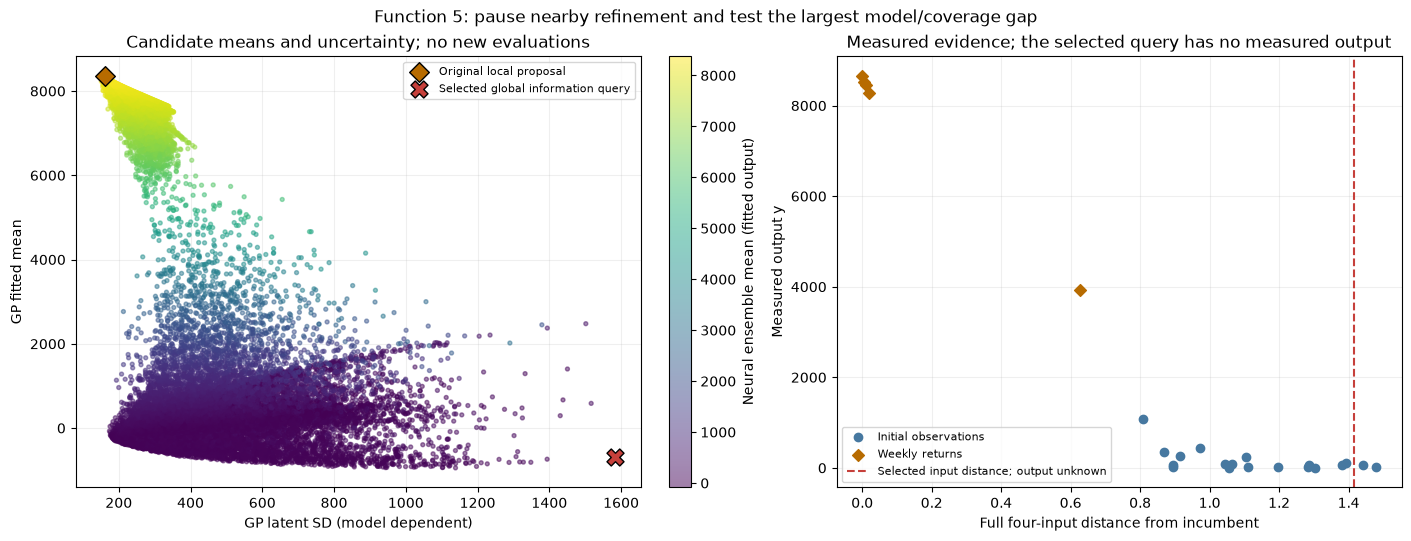

In [8]:
review5 = read_review(5)
d = review5["data"]
columns = review5["fitted"]["input_columns"]
anchor = np.asarray(review5["fitted"]["incumbent"])
choice = f5["alternatives"]["global_information_query"]
local = f5["alternatives"]["original_gp_ucb"]
figure, axes = plt.subplots(1, 2, figsize=(14, 5.3), layout="constrained")
colours = axes[0].scatter(f5_pool.gp_latent_sd, f5_pool.gp_mean, c=f5_pool.neural_mean,
    cmap="viridis", s=8, alpha=.5, rasterized=True)
figure.colorbar(colours, ax=axes[0], label="Neural ensemble mean (fitted output)")
axes[0].scatter(local["gp_latent_sd"], local["gp_mean"], marker="D", s=100,
    color="#b76b00", edgecolor="black", label="Original local proposal", zorder=5)
axes[0].scatter(choice["gp_latent_sd"], choice["gp_mean"], marker="X", s=150,
    color="#c6403b", edgecolor="black", label="Selected global information query", zorder=5)
axes[0].set(xlabel="GP latent SD (model dependent)", ylabel="GP fitted mean",
            title="Candidate means and uncertainty; no new evaluations")
axes[0].legend(fontsize=8)
distance = np.linalg.norm(d[columns].to_numpy()-anchor, axis=1)
for mask, label, marker, colour in [(d.source_round.eq(0), "Initial observations", "o", "#4678a0"),
                                    (d.source_round.gt(0), "Weekly returns", "D", "#b76b00")]:
    axes[1].scatter(distance[mask], d.loc[mask,"y"], label=label, marker=marker, color=colour)
axes[1].axvline(np.linalg.norm(np.asarray(choice["point"])-anchor), color="#c6403b", linestyle="--",
    label="Selected input distance; output unknown")
axes[1].set(xlabel="Full four-input distance from incumbent", ylabel="Measured output y",
            title="Measured evidence; the selected query has no measured output")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2);ax.set_axisbelow(True)
figure.suptitle("Function 5: pause nearby refinement and test the largest model/coverage gap")
figure.savefig(figures / "function-5-exploration-review.png", dpi=160, bbox_inches="tight")
plt.close(figure)
display(figure)


## Function 6: a focused neural candidate

The roughly 4% overall neural RMSE gain is modest, and weekly-target RMSE is worse. The saved neural candidate nevertheless has a better mean than the original GP-UCB candidate under both model families and all three selected neural seeds. Choose it for one focused test, accepting less GP uncertainty reduction. The GP's separate mean-only candidate remains visible as an alternative; there is no unique cross-model optimum.

**Agreed:** use **`0.398303-0.269220-0.627336-0.768441-0.000000`** for one focused neural-led test. Retain the modest overall error gain, worse weekly-target error, tiny predicted improvement, GP disagreement and x5=0 extrapolation as caveats. The 1.96 UCB multiplier does not select this point. The sixth line already matches; nothing is submitted.

In [9]:
f6 = record["function_6_review"]
display(pd.DataFrame(f6["alternatives"]).T.drop(columns=["point", "neural_seed_predictions"]))
display(pd.Series(f6["prediction_checks"]))
display(pd.Series(f6["guardrails"]))

print(f6["agreed_caveats"])
assert f6["status"] == "agreed"
assert f6["portal_input"] == "0.398303-0.269220-0.627336-0.768441-0.000000"
assert f6["one_focused_neural_led_test"]
assert f6["focused_tests_committed"] == 1
assert not f6["selection_uses_ucb_weight"]
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


,portal_input,gp_mean,gp_latent_sd,gp_ucb_1_96,neural_mean,neural_seed_sd,inside_selected_gp_training_hull,nearest_known_input_distance
original_gp_ucb,0.470286-0.366388-0.723696-0.848362-0.000000,-0.454159,0.160542,-0.139496,-0.507858,0.110737,False,0.252766
gp_mean_only,0.440478-0.300403-0.565546-0.790678-0.101469,-0.347673,0.065261,-0.219762,-0.449379,0.09353,True,0.119283
selected_neural_candidate,0.398303-0.269220-0.627336-0.768441-0.000000,-0.394068,0.081577,-0.234176,-0.363497,0.075254,False,0.102747


gp_rmse                                                                         0.339648
neural_rmse                                                                     0.326054
gp_mae                                                                           0.26697
neural_mae                                                                      0.261343
gp_weekly_target_rmse                                                           0.327887
neural_weekly_target_rmse                                                       0.359079
weekly_target_count                                                                    5
neural_smaller_absolute_error_cases                                                   11
scoring_cases                                                                         25
gp_latest_held_out_error                                                         0.15881
neural_latest_held_out_error                                                    0.013737
note                 

neural_rmse_lower                                    True
neural_mae_lower                                     True
gp_mean_higher_at_neural_candidate                   True
all_selected_neural_seeds_prefer_neural_candidate    True
dtype: bool

The overall neural RMSE gain is only about 4%, while error on the five weekly targets is worse. The proposed mean gain over the incumbent is only about 0.0152, far below held-out error. The GP mean at this point remains below the incumbent and the GP prefers its own mean-only candidate. The full-input point extrapolates on x5=0. Neural seed variation is not posterior uncertainty; the 1.96 multiplier does not select this point.


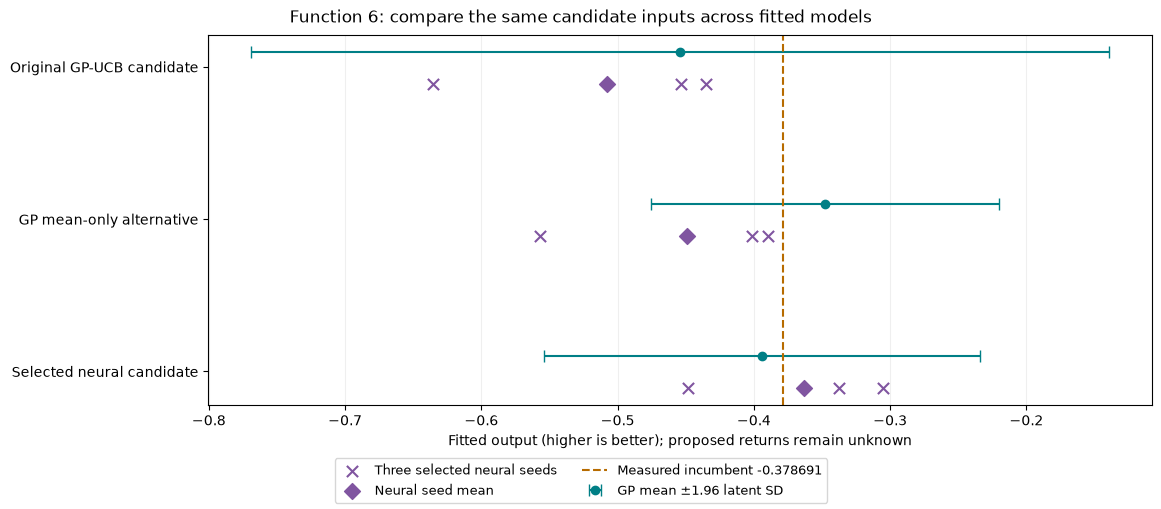

In [10]:
choices = [("Original GP-UCB candidate", f6["alternatives"]["original_gp_ucb"]),
           ("GP mean-only alternative", f6["alternatives"]["gp_mean_only"]),
           ("Selected neural candidate", f6["alternatives"]["selected_neural_candidate"])]
figure, ax = plt.subplots(figsize=(11.5,5), layout="constrained")
for i, (label, row) in enumerate(choices):
    ax.errorbar(row["gp_mean"], i-.10, xerr=1.96*row["gp_latent_sd"], fmt="o", color="#007f86",
        capsize=4, label="GP mean ±1.96 latent SD" if i==0 else None)
    ax.scatter(row["neural_seed_predictions"], [i+.11]*3, marker="x", color="#8055a0", s=65,
        label="Three selected neural seeds" if i==0 else None)
    ax.scatter(row["neural_mean"], i+.11, marker="D", color="#8055a0", s=65,
        label="Neural seed mean" if i==0 else None)
incumbent = record["candidates"][5]["evidence"]["best_official_raw_output"]
ax.axvline(incumbent, linestyle="--", color="#b76b00", label=f"Measured incumbent {incumbent:.6f}")
ax.set(yticks=range(len(choices)), yticklabels=[r[0] for r in choices],
    xlabel="Fitted output (higher is better); proposed returns remain unknown")
ax.invert_yaxis();ax.grid(axis="x", alpha=.2);ax.set_axisbelow(True)
figure.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2, fontsize=9)
figure.suptitle("Function 6: compare the same candidate inputs across fitted models")
figure.savefig(figures / "function-6-candidate-review.png", dpi=160, bbox_inches="tight")
plt.close(figure)
display(figure)


## Function 7: agreed GP-UCB input with its caveats

Keep **`0.000000-0.135108-0.370684-0.306265-0.311144-0.649736`** with weight **1.96**. The prepared seventh line already matches. The GP mean **2.481353** is below the measured incumbent **2.618968**; UCB **2.846131** is an optimistic ranking score, not a returned-value forecast. The full six-input point extrapolates on x1=0, its SD is conditional on the model, and its exact location changes with the uncertainty weight. An improvement and an optimal multiplier remain unestablished.

See the [Function 7 comparison](../../notebooks/Function_7/Week_06/report.md). All eight choices are now agreed; submission remains on hold. Nothing is submitted.

In [11]:
f7 = record["function_7_review"]
display(pd.Series(f7))
assert f7["status"] == "agreed"
assert f7["portal_input"] == "0.000000-0.135108-0.370684-0.306265-0.311144-0.649736"
assert f7["effective_ucb_weight"] == 1.96
assert "x1=0" in f7["agreed_caveats"]
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]


decision                                                  retained_gp_ucb
status                                                             agreed
effective_ucb_weight                                                 1.96
portal_input            0.000000-0.135108-0.370684-0.306265-0.311144-0...
rationale               Retain the GP-UCB local candidate. GP RMSE is ...
agreed_caveats          The GP mean at the point is below the measured...
dtype: object

## Function 8: agreed GP-UCB input with its caveats

Keep **`0.022327-0.096114-0.237034-0.202848-0.982361-0.880106-0.159960-0.678158`** with weight **1.96**, agreed on **31 October 2026**. The prepared eighth line already matches. Only 45 observations support this eight-dimensional fit. The point lies outside the sampled hull, approximately 0.754759 from its nearest observation. Its GP mean gain is below held-out error, the neural margin is tiny, and a different candidate has a near-identical UCB. Conditional uncertainty, weight sensitivity and finite-pool limits preclude claiming a uniquely best input or a guaranteed improvement.

See the [Function 8 comparison](../../notebooks/Function_8/Week_06/report.md). All eight choices and their caveats are now agreed. Nothing is submitted.

In [12]:
f8 = record["function_8_review"]
display(pd.Series(f8))
assert f8["status"] == "agreed"
assert f8["agreed_on"] == "2026-10-31"
assert f8["portal_input"] == "0.022327-0.096114-0.237034-0.202848-0.982361-0.880106-0.159960-0.678158"
assert f8["effective_ucb_weight"] == 1.96
assert record["agreed_functions"] == [1, 2, 3, 4, 5, 6, 7, 8]
assert record["selections_finalised_on"] == "2026-10-31"
assert all(c["decision_status"] == "agreed" for c in record["candidates"])
assert not record["portal_submission_performed_by_this_workflow"]


decision                                                  retained_gp_ucb
status                                                             agreed
agreed_on                                                      2026-10-31
effective_ucb_weight                                                 1.96
portal_input            0.022327-0.096114-0.237034-0.202848-0.982361-0...
rationale               Retain the full-input GP-UCB candidate, with a...
agreed_caveats          Only 45 observations support this eight-dimens...
dtype: object

## Submitted eight-line file and checks

The text below is the submitted file, read back from disk. Bounds, dimensions, six-decimal formatting and duplicates were checked against official/retained peer observations and all five earlier weekly input files. The owner confirmed submission on 31 October 2026; results are pending. This notebook does not perform a portal submission.

In [13]:
print(submission_text, end="")
display(pd.DataFrame([c["validation"] for c in record["candidates"]]).set_index("function"))
assert record["new_course_evaluations"] == 0
assert not record["portal_submission_performed_by_this_workflow"]

assert record["status"] == "submitted_awaiting_results"
assert record["remaining_queries_per_function_after_submission"] == 7
assert record["official_observations"] == 215
assert record["submission_confirmation"]["exact_portal_timestamp"] is None


0.537942-0.522217
0.700520-0.000114
0.721213-0.830963-0.001845
0.408963-0.412546-0.416464-0.438393
0.000000-0.000000-0.999999-0.999999
0.398303-0.269220-0.627336-0.768441-0.000000
0.000000-0.135108-0.370684-0.306265-0.311144-0.649736
0.022327-0.096114-0.237034-0.202848-0.982361-0.880106-0.159960-0.678158


,known_rows_checked,prior_submission_files_checked,duplicate,nearest_known_input_distance
function,,,,
1,21,5,False,0.003364
2,20,5,False,0.128630
3,25,5,False,0.173193
4,41,5,False,0.018571
5,25,5,False,0.731397
6,25,5,False,0.102747
7,35,5,False,0.133443
8,45,5,False,0.754759
